# Session 3: Embeddings, Vector Databases and Retrieval

Session 2: the LLM answers from what it learned in training. It does not know **your** documents.
Next session we build RAG: find the right pieces of your documents, then let the LLM answer from them.

Today is the **"find the right pieces"** half. We build it from first principles:

1. Why keyword search fails on real questions
2. Embeddings: turning meaning into numbers (and computing one by hand)
3. Semantic search with plain numpy
4. Why a vector database, and how Chroma stores and searches vectors
5. The LangChain versions: `Document`, embeddings, vector store, retriever
6. LCEL building blocks that will become RAG next session

| Part | What we do |
|---|---|
| 0 | Setup and data |
| 1 | Keyword search and where it breaks |
| 2 | Embeddings under the hood |
| 3 | Semantic search with numpy |
| 4 | Chroma: a real vector database |
| 5 | LangChain: Documents, embeddings, vector store, retriever |
| 6 | Building blocks for RAG |
| 7 | Exercises |

**Data:** 40 FAQs of a fictional bank, "Sahyadri Digital Bank" (`data/bank_faq.csv`).

**Runs locally, free.** The embedding model (about 90 MB) downloads once from Hugging Face on first use. Only Part 6 calls the LLM API.

**Student copy:** cells marked `TODO` are written together in class. The complete notebook is shared after the session.

## Setup: run this cell first

Choose the provider and model in the cell below. The API key is **not** written here: it stays in the `.env` file in this folder, for example:

```
OPENROUTER_API_KEY=sk-or-v1-...
```

In [1]:
# ===================== SETUP: run this cell first =====================
PROVIDER = "openrouter"    # "openrouter", "gemini" or "openai"
MODEL = ""                 # leave empty to use the default model below

import os
from dotenv import load_dotenv

# read the .env file in this folder (override=True picks up edits without restarting the kernel)
if not os.path.exists(".env"):
    raise FileNotFoundError("No .env file in this folder. Create it and add your API key.")
load_dotenv()

if PROVIDER == "openrouter":
    KEY_NAME = "OPENROUTER_API_KEY"
    MODEL = MODEL or "google/gemini-2.5-flash-lite"
    BASE_URL = "https://openrouter.ai/api/v1"
elif PROVIDER == "gemini":
    KEY_NAME = "GOOGLE_API_KEY"
    MODEL = MODEL or "gemini-2.5-flash-lite"
    BASE_URL = "https://generativelanguage.googleapis.com/v1beta/openai/"
elif PROVIDER == "openai":
    KEY_NAME = "OPENAI_API_KEY"
    MODEL = MODEL or "gpt-4.1-mini"
    BASE_URL = "https://api.openai.com/v1"
else:
    raise ValueError('PROVIDER must be "openrouter", "gemini" or "openai"')

API_KEY = os.getenv(KEY_NAME)
if not API_KEY:
    raise ValueError(f"{KEY_NAME} is missing. Add it to the .env file in this folder.")


def get_chat_model(temperature=0, **kwargs):
    """LangChain chat model for the chosen provider."""
    if PROVIDER == "openrouter":
        from langchain_openrouter import ChatOpenRouter
        return ChatOpenRouter(model=MODEL, api_key=API_KEY, base_url=BASE_URL, temperature=temperature, **kwargs)
    elif PROVIDER == "gemini":
        from langchain_google_genai import ChatGoogleGenerativeAI
        return ChatGoogleGenerativeAI(model=MODEL, api_key=API_KEY, temperature=temperature, **kwargs)
    else:
        from langchain_openai import ChatOpenAI
        return ChatOpenAI(model=MODEL, api_key=API_KEY, base_url=BASE_URL, temperature=temperature, **kwargs)


def get_openai_client():
    """Plain OpenAI SDK client pointed at the chosen provider. Returns (client, model)."""
    from openai import OpenAI
    return OpenAI(api_key=API_KEY, base_url=BASE_URL), MODEL


def show_config():
    """Print the settings without showing the full key."""
    print(f"provider : {PROVIDER}")
    print(f"model    : {MODEL}")
    print(f"key      : {KEY_NAME} = {API_KEY[:6]}...{API_KEY[-2:]} ({len(API_KEY)} chars)")
    print(f"endpoint : {BASE_URL}")


show_config()

provider : openrouter
model    : google/gemini-2.5-flash-lite
key      : OPENROUTER_API_KEY = sk-or-...1d (73 chars)
endpoint : https://openrouter.ai/api/v1


## Part 0: Setup

In [2]:
import os
import time
import shutil

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F

import sentence_transformers
import chromadb
import langchain_core

print("sentence-transformers:", sentence_transformers.__version__)
print("chromadb             :", chromadb.__version__)
print("langchain-core       :", langchain_core.__version__)
print("torch                :", torch.__version__)

sentence-transformers: 6.1.0
chromadb             : 1.5.9
langchain-core       : 1.6.7
torch                : 2.14.1+cu130


Load the FAQ data and look at it. Each row: an id, a category, a question and its answer.

In [3]:
faq = pd.read_csv("data/bank_faq.csv")
print(faq.shape)
print(faq["category"].value_counts().to_dict())
faq.head()

(40, 4)
{'accounts': 9, 'cards': 9, 'loans': 8, 'app': 8, 'security': 6}


,id,category,question,answer
0,faq01,accounts,How do I open a savings account?,You can open a savings account in the app unde...
1,faq02,accounts,What is the minimum balance for a savings acco...,The Regular savings account needs an average m...
2,faq03,accounts,How can I close my account?,Raise a closure request in the app under Profi...
3,faq04,accounts,How do I download my account statement?,Go to Accounts > Statements in the app and cho...
4,faq05,accounts,How do I add a nominee to my account?,Open Profile > Nominee and add the nominee's n...


In [4]:
faq['category'].value_counts()

category
accounts    9
cards       9
loans       8
app         8
security    6
Name: count, dtype: int64

## Part 1: Keyword search and where it breaks

You already know **TF-IDF** from earlier sessions: each text becomes a vector of word weights; similar texts share words. Let us build a tiny FAQ search with it.

In [5]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

tfidf = TfidfVectorizer(stop_words="english")
tfidf_matrix = tfidf.fit_transform(faq["question"])
print("TF-IDF matrix:", tfidf_matrix.shape, "(questions x vocabulary words)")

def keyword_search(query, k=3):
    scores = cosine_similarity(tfidf.transform([query]), tfidf_matrix)[0]
    top = np.argsort(scores)[::-1][:k]
    return pd.DataFrame({"score": scores[top].round(3), "question": faq["question"].iloc[top].values})

TF-IDF matrix: (40, 82) (questions x vocabulary words)


A query that uses the **same words** as the FAQ works:

In [6]:
keyword_search("how do I block my debit card")

,score,question
0,1.000,How do I block my debit card?
1,0.440,Can I use my debit card abroad?
2,0.426,Is there an annual fee for the debit card?


Now the way real customers write. None of these share key words with the right FAQ:

| Customer writes | Right FAQ |
|---|---|
| I forgot my login credentials | I forgot my app password. How do I reset it? |
| my wallet got pickpocketed with my card in it | My card was stolen. What should I do? |
| a man on the phone wants my one time code | Someone called asking for my OTP. Is this the bank? |

In [7]:
queries = [
    "I forgot my login credentials",
    "my wallet got pickpocketed with my card in it",
    "a man on the phone wants my one time code",
]

for q in queries:
    print("QUERY:", q)
    print(keyword_search(q).to_string(index=False))
    print()

QUERY: I forgot my login credentials
 score                                     question
 0.408           How do I enable fingerprint login?
 0.383 I forgot my app password. How do I reset it?
 0.000   Is there an annual fee for the debit card?

QUERY: my wallet got pickpocketed with my card in it
 score                              question
 0.571      When is my credit card bill due?
 0.531 My card was stolen. What should I do?
 0.434         How do I block my debit card?

QUERY: a man on the phone wants my one time code
 score                                   question
 0.707      What should I do if my phone is lost?
 0.000 Is there an annual fee for the debit card?
 0.000        Can I open an account for my child?



Scores of 0 or wrong matches. Keyword search matches **words**, not **meaning**. "credentials" and "password" share no letters, but mean nearly the same thing here. We need vectors that capture meaning.

## Part 2: Embeddings

An **embedding model** turns a whole sentence into a fixed-length list of numbers (a vector) such that sentences with **similar meaning get similar vectors**, even with no shared words.

- You met word embeddings (CBOW) earlier: one vector per **word**.
- A sentence embedding model is a small **transformer** (like DistilBERT in Session 1) trained on millions of sentence pairs, so that paraphrases land close together.

**Analogy:** a library that shelves books by *topic*, not by the first letter of the title. A book about "credit cards" sits next to one about "debit cards", even though the titles start differently.

We use `all-MiniLM-L6-v2`: small (about 90 MB), fast on CPU, 384 numbers per sentence, English only.

In [8]:
from sentence_transformers import SentenceTransformer

EMBED_MODEL = "sentence-transformers/all-MiniLM-L6-v2"

embedder = SentenceTransformer(EMBED_MODEL)
print(embedder)
print("vector size:", embedder.get_embedding_dimension())   # older versions: get_sentence_embedding_dimension()
print("max tokens :", embedder.max_seq_length)

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

SentenceTransformer(
  (0): Transformer({'transformer_task': 'feature-extraction', 'modality_config': {'text': {'method': 'forward', 'method_output_name': 'last_hidden_state'}}, 'module_output_name': 'token_embeddings', 'architecture': 'BertModel'})
  (1): Pooling({'embedding_dimension': 384, 'pooling_mode': 'mean', 'include_prompt': True})
  (2): Normalize({'module_input_name': 'sentence_embedding', 'module_output_name': 'sentence_embedding'})
)
vector size: 384
max tokens : 256


The printout shows three steps: a **Transformer**, then **Pooling** (mean), then **Normalize**. Keep these in mind; we will rebuild them by hand in a moment.

Embed one sentence:

In [9]:
vec = embedder.encode("How do I block my debit card?", normalize_embeddings=True)

print("type  :", type(vec).__name__, vec.dtype)
print("shape :", vec.shape)
print("first 8 numbers:", vec[:8].round(4))
print("length (norm):", round(float(np.linalg.norm(vec)), 4))

type  : ndarray float32
shape : (384,)
first 8 numbers: [-0.03    0.1071 -0.0326 -0.0422 -0.0227 -0.0373  0.0696 -0.0628]
length (norm): 1.0


The individual numbers mean nothing on their own. What matters is **distance between vectors**. The norm is 1 because we normalized: all vectors sit on a sphere, and only their **direction** carries meaning.

### Cosine similarity, by hand

Cosine similarity = how much two vectors point the same way.

```
cos(a, b) = (a . b) / (|a| x |b|)
```

1 = same direction, 0 = unrelated, negative = opposite. For normalized vectors, |a| = |b| = 1, so cosine is just the **dot product**.

In [10]:
sentences = [
    "How do I block my debit card?",
    "My card was stolen, what should I do?",
    "I forgot my login credentials",
    "How do I reset my app password?",
    "What is the interest rate on home loans?",
]

vectors = embedder.encode(sentences, normalize_embeddings=True)
print("matrix shape:", vectors.shape)

def cosine(a, b):
    # TODO: dot product of a and b, divided by (norm of a x norm of b)
    return float(np.dot(a, b) / np.linalg.norm(a) * np.linalg.norm(b))

print("all vectors:", vectors)

print("\ncredentials vs reset password:", round(cosine(vectors[2], vectors[3]), 3))
print("credentials vs home loans    :", round(cosine(vectors[2], vectors[4]), 3))

matrix shape: (5, 384)
all vectors: [[-0.03003135  0.10708005 -0.0325948  ... -0.00648914  0.0192832
   0.02288641]
 [-0.05449919  0.06723551  0.01573209 ... -0.01473238 -0.05114375
  -0.02229213]
 [-0.02265183 -0.01048859  0.00083871 ...  0.06461154 -0.07118094
  -0.10038789]
 [-0.01622845 -0.03223881 -0.05429051 ...  0.04893181 -0.03552205
  -0.06608313]
 [ 0.06309745 -0.00314951 -0.08826618 ... -0.00946633 -0.02347925
  -0.05477034]]

credentials vs reset password: 0.581
credentials vs home loans    : -0.067


All pairs at once: a matrix multiplication of the vectors with themselves gives every pairwise cosine. The heatmap makes the structure visible.

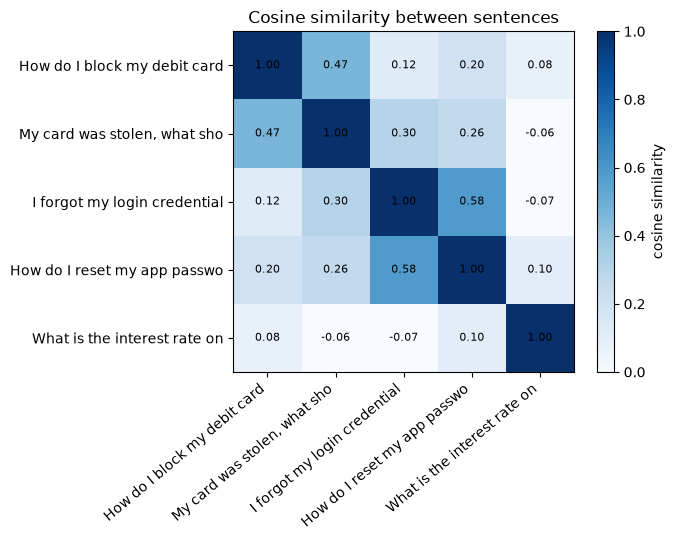

True


In [11]:
sim = vectors @ vectors.T

short = [s[:28] for s in sentences]
plt.figure(figsize=(7, 5.5))
plt.imshow(sim, cmap="Blues", vmin=0, vmax=1)
plt.colorbar(label="cosine similarity")
plt.xticks(range(len(short)), short, rotation=40, ha="right")
plt.yticks(range(len(short)), short)
for i in range(len(sentences)):
    for j in range(len(sentences)):
        plt.text(j, i, f"{sim[i, j]:.2f}", ha="center", va="center", fontsize=8)
plt.title("Cosine similarity between sentences")
plt.tight_layout()
plt.show()

# the library's own function gives the same numbers
print(np.allclose(sim, embedder.similarity(vectors, vectors).numpy(), atol=1e-5))

### Under the hood: rebuilding the embedding by hand

`embedder.encode()` does exactly what you saw in Session 1, plus one step:

1. **Tokenize** (word pieces, `[CLS]`, `[SEP]`, attention mask)
2. **Transformer** -> one 384-number vector **per token**
3. **Mean pooling** -> average the token vectors (ignoring padding) -> one vector per sentence
4. **Normalize** -> length 1

We load the same model with plain `transformers` and do the four steps ourselves. If our numbers match the library's, there is no magic left.

In [12]:
from transformers import AutoTokenizer, AutoModel

hf_tokenizer = AutoTokenizer.from_pretrained(EMBED_MODEL)
hf_model = AutoModel.from_pretrained(EMBED_MODEL).eval()

two = sentences[:2]

# 1. tokenize
enc = hf_tokenizer(two, padding=True, truncation=True, return_tensors="pt")
print("tokens of sentence 1:", hf_tokenizer.convert_ids_to_tokens(enc["input_ids"][0]))

# 2. transformer: one vector per token
with torch.no_grad():
    token_vectors = hf_model(**enc).last_hidden_state
print("token vectors shape :", tuple(token_vectors.shape), "-> (sentences, tokens, dims)")

# 3. mean pooling, ignoring padded positions
mask = enc["attention_mask"].unsqueeze(-1).float()
mean_pooled = (token_vectors * mask).sum(dim=1) / mask.sum(dim=1)

# 4. normalize to length 1
manual = F.normalize(mean_pooled, dim=1).numpy()

library = embedder.encode(two, normalize_embeddings=True)
print("max difference vs library:", float(np.abs(manual - library).max()))
print("same result:", np.allclose(manual, library, atol=1e-4))

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

tokens of sentence 1: ['[CLS]', 'how', 'do', 'i', 'block', 'my', 'de', '##bit', 'card', '?', '[SEP]', '[PAD]']
token vectors shape : (2, 12, 384) -> (sentences, tokens, dims)
max difference vs library: 1.4901161193847656e-08
same result: True


### Seeing meaning as positions

384 dimensions cannot be drawn, so we squash them to 2 with PCA (keeps the directions with most variation). Sentences from four topics:

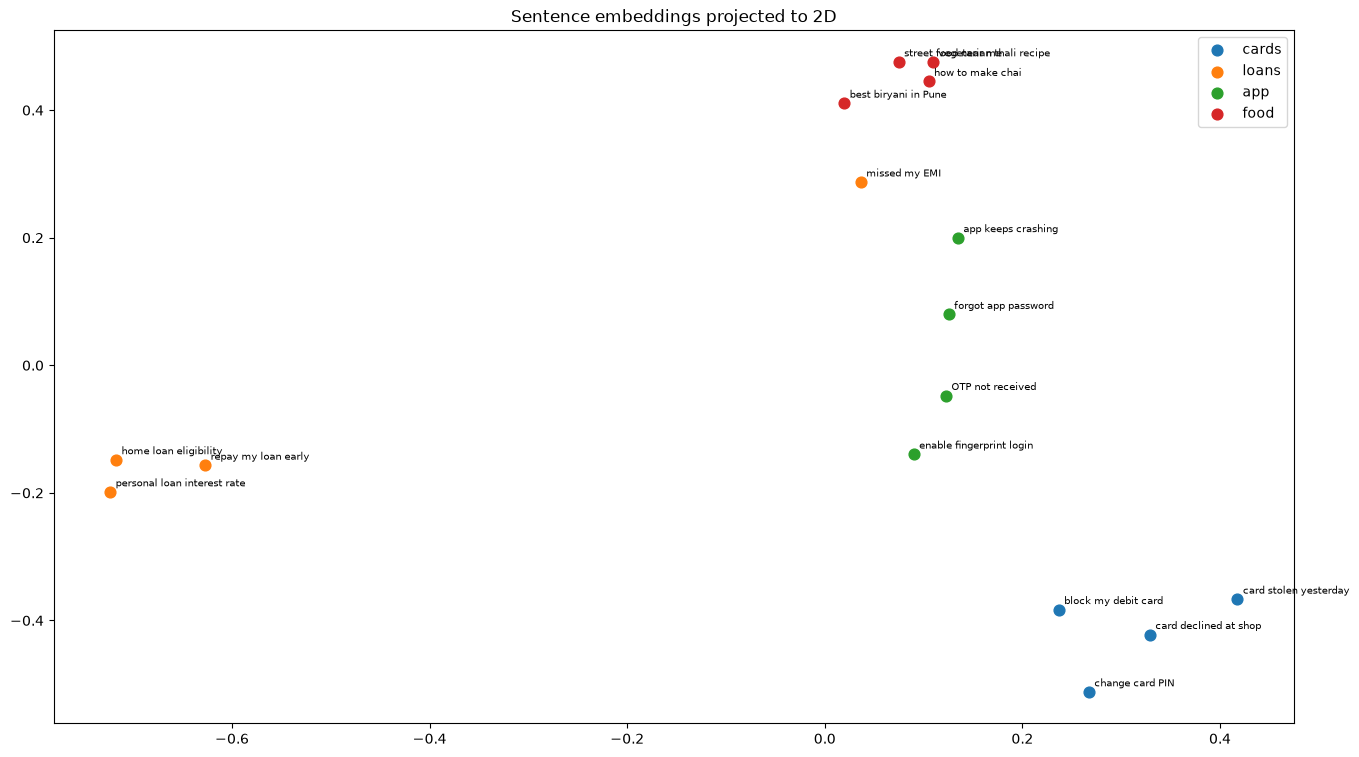

In [14]:
from sklearn.decomposition import PCA

topic_sentences = {
    "cards": ["block my debit card", "card stolen yesterday", "change card PIN", "card declined at shop"],
    "loans": ["personal loan interest rate", "repay my loan early", "home loan eligibility", "missed my EMI"],
    "app": ["app keeps crashing", "forgot app password", "OTP not received", "enable fingerprint login"],
    "food": ["best biryani in Pune", "how to make chai", "vegetarian thali recipe", "street food near me"],
}

labels, texts = [], []
for topic, items in topic_sentences.items():
    labels += [topic] * len(items)
    texts += items

points = PCA(n_components=2).fit_transform(embedder.encode(texts, normalize_embeddings=True))

plt.figure(figsize=(16, 9))
for topic in topic_sentences:
    idx = [i for i, l in enumerate(labels) if l == topic]
    plt.scatter(points[idx, 0], points[idx, 1], label=topic, s=60)
    for i in idx:
        plt.annotate(texts[i], points[i], fontsize=7, xytext=(4, 4), textcoords="offset points")
plt.legend()
plt.title("Sentence embeddings projected to 2D")
plt.show()

Sentences of the same topic cluster together. The food sentences sit far from banking. (PCA loses most of the 384 dimensions, so clusters in 2D are only a rough picture.)

### Where embeddings struggle

Know the limits before you trust them:

In [15]:
pairs = [
    ("I want to block my card", "I do not want to block my card"),      # negation
    ("Transfer 500 rupees to Riya", "Transfer 50000 rupees to Riya"),     # numbers
    ("I want to block my card", "मुझे अपना कार्ड ब्लॉक करना है"),          # Hindi, same meaning
]

for a, b in pairs:
    va, vb = embedder.encode([a, b], normalize_embeddings=True)
    print(f"{cosine(va, vb):.3f} | {a}  <->  {b}")

0.973 | I want to block my card  <->  I do not want to block my card
0.926 | Transfer 500 rupees to Riya  <->  Transfer 50000 rupees to Riya
0.084 | I want to block my card  <->  मुझे अपना कार्ड ब्लॉक करना है


- **Negation** and **numbers**: very high similarity even though the meaning is opposite or very different. Embeddings capture *topic* strongly, *exact details* weakly. This is why RAG still needs the LLM to read the retrieved text carefully.
- **Other languages**: this model is English-only, so the Hindi sentence is not recognised as the same request. For Hindi or Marathi data, use a multilingual model such as `paraphrase-multilingual-MiniLM-L12-v2` (Exercise 3).

## Part 3: Semantic search with plain numpy

The whole idea of semantic search in four steps:

1. Embed every FAQ question once (offline).
2. Embed the user's query.
3. Score = dot product of the query vector with every FAQ vector.
4. Return the top k.

In [16]:
faq_vectors = embedder.encode(faq["question"].tolist(), normalize_embeddings=True)
print("FAQ matrix:", faq_vectors.shape)

def semantic_search(query, k=3):
    # TODO 1: embed the query (normalized)
    q = embedder.encode(query, normalize_embeddings= True)
    # TODO 2: scores = dot product of faq_vectors with the query vector
    scores = faq_vectors @ q
    # TODO 3: indexes of the top k scores, highest first
    top = np.argsort(scores)[::-1][:k]
    # TODO 4: return a DataFrame with score and question
    
    return pd.DataFrame({'scores': scores[top].round(3),
                         'question': faq['question'].iloc[top].values})

FAQ matrix: (40, 384)


In [18]:
semantic_search('How do I block my debit card?')

,scores,question
0,1.000,How do I block my debit card?
1,0.542,Can I use my debit card abroad?
2,0.495,How do I set or change my card PIN?


Same three hard queries, keyword vs semantic, side by side:

In [19]:
for q in queries:
    print("QUERY:", q)
    print("  keyword :", keyword_search(q, k=1).iloc[0].to_dict())
    print("  semantic:", semantic_search(q, k=1).iloc[0].to_dict())
    print()

QUERY: I forgot my login credentials
  keyword : {'score': 0.408, 'question': 'How do I enable fingerprint login?'}
  semantic: {'scores': 0.6579999923706055, 'question': 'I forgot my app password. How do I reset it?'}

QUERY: my wallet got pickpocketed with my card in it
  keyword : {'score': 0.571, 'question': 'When is my credit card bill due?'}
  semantic: {'scores': 0.6259999871253967, 'question': 'My card was stolen. What should I do?'}

QUERY: a man on the phone wants my one time code
  keyword : {'score': 0.707, 'question': 'What should I do if my phone is lost?'}
  semantic: {'scores': 0.3869999945163727, 'question': 'How do I change my registered mobile number?'}



Look at the scores too. A semantic score is never exactly 0 - every query finds *something*. Real systems often set a **minimum score** and say "no good match" below it.

In [20]:
print(semantic_search("what is the best biryani in Pune", k=3))

   scores                                   question
0    0.11                I am not receiving the OTP.
1    0.09  The app keeps crashing. What should I do?
2    0.09            How do I set up UPI in the app?


### Why not stop here?

Brute-force search compares the query with **every** vector. Fine for 40 FAQs. Let us time it at a larger scale with random vectors.

In [21]:
for n_docs in [40, 10_000, 100_000]:
    fake = np.random.rand(n_docs, 384).astype("float32")
    q = np.random.rand(384).astype("float32")
    start = time.perf_counter()
    for _ in range(20):
        top = np.argsort(fake @ q)[::-1][:3]
    ms = (time.perf_counter() - start) / 20 * 1000
    print(f"{n_docs:>8,} vectors: {ms:7.2f} ms per query, {fake.nbytes / 1e6:6.1f} MB in RAM")

      40 vectors:    0.01 ms per query,    0.1 MB in RAM
  10,000 vectors:    2.18 ms per query,   15.4 MB in RAM
 100,000 vectors:    9.54 ms per query,  153.6 MB in RAM


Time and memory grow with every document, and we also lack:
- **persistence** (vectors vanish when Python stops),
- **metadata filters** ("only cards questions"),
- **updates and deletes** by id.

A **vector database** gives all of this, and uses an approximate index (**HNSW**) so search stays fast at millions of vectors.

**HNSW intuition:** like finding a house using highways, then main roads, then lanes. The index links each vector to a few near neighbours in layers; search hops from coarse to fine instead of checking every house. It is *approximate*: very rarely it misses the exact best match, in exchange for huge speed.

## Part 4: Chroma, a real vector database

Chroma runs inside your Python process and saves to a folder on disk. No server, no account.

Concepts:

| Chroma | Like in a SQL database |
|---|---|
| client | the database connection |
| collection | a table |
| id | primary key |
| document | the text |
| embedding | the vector |
| metadata | extra columns you can filter on |

We start clean: delete any collections left from a previous run, so reruns give the same result. (Deleting through the client is safer than deleting the folder: on Windows the folder's files stay locked while a client is open.)

In [22]:
import chromadb

DB_DIR = "chroma_db"
client = chromadb.PersistentClient(path=DB_DIR)

for old in client.list_collections():
    client.delete_collection(old.name)

print(client)
print("collections:", [c.name for c in client.list_collections()])

collections: []


**Distance metric.** Chroma's default distance is *squared L2* (straight-line distance). For text embeddings we want **cosine**, set when the collection is created. We also pass `embedding_function=None` because we bring our own vectors.

A small rule to know: collection names need 3 to 512 characters (letters, digits, `.`, `_`, `-`).

In [23]:
try:
    client.create_collection("ab", embedding_function=None)
except Exception as e:
    print(type(e).__name__, "->", str(e)[:120])

InvalidArgumentError -> Validation error: name: Expected a name containing 3-512 characters from [a-zA-Z0-9._-], starting and ending with a char


In [24]:
collection = client.create_collection(
    name="bank_faq",
    configuration={"hnsw": {"space": "cosine"}},
    embedding_function=None,
)

# TODO: add ids, documents (questions), embeddings (faq_vectors)
#       and metadatas (category + answer) to the collection
collection.add(
    ids = faq['id'].tolist(),
    documents= faq['question'].tolist(),
    embeddings= faq_vectors,
    metadatas= faq[['category', 'answer']].to_dict(orient= "records"),

)


print("stored:", collection.count())
print("config:", collection.configuration["hnsw"]["space"])

stored: 40
config: cosine


Query with a vector. Chroma returns **distances** (lower = closer). For cosine space, `distance = 1 - cosine similarity`.

In [26]:
query = "someone is asking for otp"
q_vec = embedder.encode(query, normalize_embeddings=True)

result = collection.query(
    query_embeddings=[q_vec],
    n_results=3,
    include=["documents", "distances", "metadatas"],
)

print("keys:", list(result.keys()))
print("ids :", result["ids"])

# results are lists of lists: one inner list per query we sent
for doc_id, doc, dist, meta in zip(result["ids"][0], result["documents"][0], result["distances"][0], result["metadatas"][0]):
    print(f"{doc_id} | distance={dist:.3f} similarity={1 - dist:.3f} | [{meta['category']}] {doc}")

keys: ['ids', 'embeddings', 'documents', 'uris', 'included', 'data', 'metadatas', 'distances']
ids : [['faq26', 'faq34', 'faq35']]
faq26 | distance=0.315 similarity=0.685 | [app] I am not receiving the OTP.
faq34 | distance=0.329 similarity=0.671 | [security] Someone called asking for my OTP. Is this the bank?
faq35 | distance=0.769 similarity=0.231 | [security] How do I know if an SMS is really from the bank?


Check against our numpy search: same top results, and `1 - distance` equals the numpy score.

In [27]:
semantic_search(query, k=3)

,scores,question
0,0.685,I am not receiving the OTP.
1,0.671,Someone called asking for my OTP. Is this the ...
2,0.231,How do I know if an SMS is really from the bank?


**Metadata filter:** search only within one category. Useful when a user is already in the "Cards" section of the app.

In [32]:
faq['category'].value_counts()

category
accounts    9
cards       9
loans       8
app         8
security    6
Name: count, dtype: int64

In [29]:
filtered = collection.query(
    query_embeddings=[embedder.encode("what is the limit", normalize_embeddings=True)],
    n_results=3,
    where={"category": "cards"},
)
for doc_id, doc in zip(filtered["ids"][0], filtered["documents"][0]):
    print(doc_id, "|", doc)

faq12 | What is the daily ATM withdrawal limit?
faq09 | How do I block my debit card?
faq40 | Is there an annual fee for the debit card?


Get, update and delete by id - a FAQ answer changes, a FAQ is retired. Chroma keeps the vector, text and metadata together.

In [33]:
print(collection.get(ids=["faq12"], include=["documents", "metadatas"]))

new_answer = "The default ATM limit is Rs 30000 per day. You can change it up to Rs 50000 in Cards > Limits."
collection.update(ids=["faq12"], metadatas=[{"category": "cards", "answer": new_answer}])
print("\nafter update:", collection.get(ids=["faq12"])["metadatas"])

collection.delete(ids=["faq40"])
print("count after delete:", collection.count())

{'ids': ['faq12'], 'embeddings': None, 'documents': ['What is the daily ATM withdrawal limit?'], 'uris': None, 'included': ['documents', 'metadatas'], 'data': None, 'metadatas': [{'answer': 'The default ATM limit is Rs 25000 per day. You can lower or raise it up to Rs 50000 in Cards > Limits.', 'category': 'cards'}]}

after update: [{'answer': 'The default ATM limit is Rs 30000 per day. You can change it up to Rs 50000 in Cards > Limits.', 'category': 'cards'}]
count after delete: 39


**Persistence:** create a brand-new client pointing at the same folder. The data is still there - this is the difference from the numpy version.

In [34]:
reopened = chromadb.PersistentClient(path=DB_DIR).get_collection("bank_faq")
print("collections on disk:", [c.name for c in chromadb.PersistentClient(path=DB_DIR).list_collections()])
print("count after reopening:", reopened.count())
print("files:", sorted(os.listdir(DB_DIR))[:5])

collections on disk: ['bank_faq']
count after reopening: 39
files: ['5494e152-1b3c-4833-9873-a37339188a0d', 'chroma.sqlite3']


### Under the hood: cosine vs L2 give the same ranking here

For **normalized** vectors, squared L2 distance and cosine are linked:

```
squared_L2(a, b) = 2 - 2 x cos(a, b)
```

So with normalized embeddings, the default L2 space ranks results in the same order; only the numbers differ. Let us verify.

In [35]:
l2_collection = client.create_collection(name="bank_faq_l2", embedding_function=None)
l2_collection.add(ids=faq["id"].tolist(), embeddings=faq_vectors)

l2 = l2_collection.query(query_embeddings=[q_vec], n_results=3)
cos = collection.query(query_embeddings=[q_vec], n_results=3)

print("L2 ids     :", l2["ids"][0])
print("cosine ids :", cos["ids"][0])
for d_l2, d_cos in zip(l2["distances"][0], cos["distances"][0]):
    print(f"squared L2 = {d_l2:.4f}   2 x cosine distance = {2 * d_cos:.4f}")

L2 ids     : ['faq26', 'faq34', 'faq35']
cosine ids : ['faq26', 'faq34', 'faq35']
squared L2 = 0.6295   2 x cosine distance = 0.6295
squared L2 = 0.6587   2 x cosine distance = 0.6587
squared L2 = 1.5370   2 x cosine distance = 1.5370


## Part 5: The LangChain way

LangChain wraps the same pieces behind standard interfaces, so in RAG you can swap Chroma for another vector database, or MiniLM for another embedding model, without rewriting the pipeline.

| Piece | LangChain class |
|---|---|
| a chunk of text + metadata | `Document` |
| the embedding model | `HuggingFaceEmbeddings` |
| the vector database | `Chroma` (from `langchain_chroma`) |
| "give me relevant documents" | a **retriever** |

### Documents

A `Document` is text (`page_content`) plus a dict of `metadata`. This time we embed **question and answer together**, so a query can match words that appear only in the answer.

In [36]:
from langchain_core.documents import Document

docs = [
    Document(
        page_content=f"Q: {row.question}\nA: {row.answer}",
        metadata={"id": row.id, "category": row.category},
    )
    for row in faq.itertuples()
]

print(len(docs), "documents")
print(docs[0])

40 documents
page_content='Q: How do I open a savings account?
A: You can open a savings account in the app under Accounts > Open New. Keep your PAN and Aadhaar ready; video KYC takes about 10 minutes.' metadata={'id': 'faq01', 'category': 'accounts'}


### Embeddings and vector store

`HuggingFaceEmbeddings` wraps the same sentence-transformers model.

**Library-change trap:** older tutorials write `HuggingFaceEmbeddings(model_name=...)` from `langchain_community`. The current class lives in `langchain_huggingface` and its argument is `model=` (`model_name` still works as an alias for now).

Passing `ids` matters: rerunning the cell then **updates** the same entries instead of adding duplicates.

In [38]:
from langchain_huggingface import HuggingFaceEmbeddings
from langchain_chroma import Chroma

# TODO: create HuggingFaceEmbeddings for EMBED_MODEL with normalized embeddings
embeddings = HuggingFaceEmbeddings(model = EMBED_MODEL, encode_kwargs = {'normalize_embeddings': True})


print("query vector length:", len(embeddings.embed_query("hello")))

# TODO: build the vector store with Chroma.from_documents
#       documents=docs, embedding=embeddings, ids from metadata,
#       collection_name="bank_faq_lc", persist_directory=DB_DIR,
#       collection_configuration with cosine space
vectorstore = Chroma.from_documents(
    documents=docs, embedding=embeddings,
    ids = [d.metadata['id'] for d in docs],
    collection_name="bank_faq_lc", persist_directory=DB_DIR,
    collection_configuration= {'hnsw': {'space': 'cosine'}}
)


print("stored:", vectorstore._collection.count())

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

query vector length: 384
stored: 40


Three ways to search. Watch the **score** column carefully - the same word "score" means different things:

- `similarity_search` - documents only
- `similarity_search_with_score` - **distance** (lower is better)
- `similarity_search_with_relevance_scores` - **relevance** 0 to 1 (higher is better)

In [39]:
query = "my wallet got pickpocketed with my card in it"

print("similarity_search:")
for d in vectorstore.similarity_search(query, k=2):
    print("  ", d.metadata["id"], d.page_content[:70])

print("\nwith_score (distance, lower = better):")
for d, s in vectorstore.similarity_search_with_score(query, k=2):
    print(f"   {s:.3f}", d.metadata["id"])

print("\nwith_relevance_scores (higher = better):")
for d, s in vectorstore.similarity_search_with_relevance_scores(query, k=2):
    print(f"   {s:.3f}", d.metadata["id"])

similarity_search:
   faq10 Q: My card was stolen. What should I do?
A: Block the card immediately
   faq11 Q: How do I set or change my card PIN?
A: Go to Cards > Set PIN in the

with_score (distance, lower = better):
   0.453 faq10
   0.586 faq11

with_relevance_scores (higher = better):
   0.547 faq10
   0.414 faq11


Metadata filter, LangChain style:

In [40]:
for d in vectorstore.similarity_search("what is the limit", k=3, filter={"category": "app"}):
    print(d.metadata, "|", d.page_content.splitlines()[0])

{'category': 'app', 'id': 'faq32'} | Q: What is the daily UPI limit?
{'id': 'faq28', 'category': 'app'} | Q: The app keeps crashing. What should I do?
{'id': 'faq26', 'category': 'app'} | Q: I am not receiving the OTP.


### Retriever

A **retriever** is the standard LangChain interface for "query in, relevant documents out". It is a Runnable, so it has `.invoke()` and `.batch()` and plugs into chains with `|`. RAG is built on this.

In [41]:
retriever = vectorstore.as_retriever(search_kwargs={"k": 3})
print(type(retriever).__name__)

results = retriever.invoke("someone on the phone wants my one time code")
for d in results:
    print(d.metadata["id"], "|", d.page_content.splitlines()[0])

VectorStoreRetriever
faq38 | Q: What should I do if my phone is lost?
faq34 | Q: Someone called asking for my OTP. Is this the bank?
faq11 | Q: How do I set or change my card PIN?


In [42]:
batch_results = retriever.batch(["home loan tenure", "UPI daily limit"])
for q, found in zip(["home loan tenure", "UPI daily limit"], batch_results):
    print(q, "->", [d.metadata["id"] for d in found])

home loan tenure -> ['faq22', 'faq19', 'faq17']
UPI daily limit -> ['faq32', 'faq12', 'faq31']


## Part 6: Building blocks for RAG

Next session's RAG chain is:

```
question -> retriever -> format the documents -> prompt (context + question) -> LLM -> answer
```

The tricky part: the prompt needs **two** inputs (context and question) but the chain receives only the question. Three small Runnables solve this:

| Runnable | What it does |
|---|---|
| `RunnableLambda(f)` | turns any Python function into a chain step |
| `RunnablePassthrough()` | passes the input through unchanged |
| `RunnableParallel({...})` | runs several steps on the same input, returns a dict |

Build it step by step and **inspect** the intermediate output before adding the LLM.

In [43]:
from langchain_core.runnables import RunnableLambda, RunnablePassthrough, RunnableParallel

def format_docs(documents):
    return "\n\n".join(f"[{d.metadata['id']}] {d.page_content}" for d in documents)

format_step = RunnableLambda(format_docs)

print(format_step.invoke(retriever.invoke("card stolen")))

[faq10] Q: My card was stolen. What should I do?
A: Block the card immediately from the app or by calling 1800-000-1111 and then request a replacement card. Report any unauthorised transactions within 3 days.

[faq38] Q: What should I do if my phone is lost?
A: Call 1800-000-1111 to block app access and your cards. Then visit a branch to update your mobile number.

[faq11] Q: How do I set or change my card PIN?
A: Go to Cards > Set PIN in the app and verify with the OTP sent to your registered mobile number.


In [44]:
# TODO: RunnableParallel with two keys:
#   "context"  -> retriever piped into format_docs
#   "question" -> RunnablePassthrough()
prepare = RunnableParallel({
    'context': retriever | format_docs,
    'question': RunnablePassthrough(),
})

prepared = prepare.invoke("I lost my phone, what do I do?")
print("keys:", list(prepared.keys()))
print("\nquestion:", prepared["question"])
print("\ncontext:\n" + prepared["context"])

keys: ['context', 'question']

question: I lost my phone, what do I do?

context:
[faq38] Q: What should I do if my phone is lost?
A: Call 1800-000-1111 to block app access and your cards. Then visit a branch to update your mobile number.

[faq10] Q: My card was stolen. What should I do?
A: Block the card immediately from the app or by calling 1800-000-1111 and then request a replacement card. Report any unauthorised transactions within 3 days.

[faq25] Q: I forgot my app password. How do I reset it?
A: Tap Forgot Password on the login screen and verify with the OTP sent to your registered mobile number.


`|` between a Runnable and a plain function (`retriever | format_docs`) wraps the function in `RunnableLambda` automatically.

Now add the prompt and the LLM from Session 2. The instruction "answer only from the context, otherwise say you do not know" is the core of RAG. This is a **preview** - Session 4 builds the full pipeline on real PDF documents.

In [45]:
from langchain_core.prompts import ChatPromptTemplate
from langchain_core.output_parsers import StrOutputParser

llm = get_chat_model(temperature=0)

prompt = ChatPromptTemplate.from_messages([
    ("system",
     "You are the support assistant of Sahyadri Digital Bank. Answer using ONLY the FAQ context. "
     "Cite the FAQ id in square brackets. If the context does not contain the answer, say you do not know."),
    ("human", "FAQ context:\n{context}\n\nQuestion: {question}"),
])

faq_bot = prepare | prompt | llm | StrOutputParser()

for q in ["I lost my phone, what do I do?",
          "Is the Platinum card free?",
          "What is the share price of the bank?"]:
    print("Q:", q)
    print("A:", faq_bot.invoke(q))
    print()

Q: I lost my phone, what do I do?
A: Call 1800-000-1111 to block app access and your cards. Then visit a branch to update your mobile number. [faq38]

Q: Is the Platinum card free?
A: No, the Platinum debit card has an annual fee of Rs 499, which is waived if your average balance is above Rs 50000. [faq40]

Q: What is the share price of the bank?
A: I do not know.



The last question has no answer in the FAQs; a well-instructed chain should say it does not know rather than invent a number.

Also try "Is the Platinum card free?" - we **deleted faq40** from the native Chroma collection, but the LangChain collection `bank_faq_lc` is separate and still has it. Same database folder, different collections.

## Part 7: Exercises

1. **Easy** - Write 5 queries of your own the way a real customer would (typos, Hinglish words, short phrases). Compare `keyword_search` and `semantic_search`. Where does semantic search still fail?
2. **Medium** - Add 3 new FAQs (your own) to `vectorstore` with `vectorstore.add_documents(docs, ids=[...])`, then find them with a filtered search.
3. **Challenge** - Load `sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2`, rerun the Hindi pair from Part 2 and a few Hindi or Marathi queries against the FAQs (embed the questions with the new model). What changes?

**Before next session (capstone):** collect 1 to 5 PDF or text documents from a domain you know (public or dummy data). Next week we build RAG on them.